In [1]:
import os
import subprocess

print("=== GPU INFORMATION ===")
result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print(result.stdout)
else:
    print("GPU not detected.")
    print(result.stderr)

print("\n=== PYTORCH GPU CHECK ===")

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Number of GPUs:", torch.cuda.device_count())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

=== GPU INFORMATION ===
Thu Oct 15 16:06:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------

In [2]:
print("=== AVAILABLE DATASET FILES ===")

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        file_path = os.path.join(root, file)
        print(file_path)

=== AVAILABLE DATASET FILES ===
/kaggle/input/datasets/sanalabs/telecom-churn-company-a/Client.csv
/kaggle/input/datasets/sanalabs/telecom-churn-company-a/Record.csv


In [3]:
import pandas as pd

# Dataset paths
DATA_PATH = "/kaggle/input/datasets/sanalabs/telecom-churn-company-a"

client_path = f"{DATA_PATH}/Client.csv"
record_path = f"{DATA_PATH}/Record.csv"

# Load datasets
df_client = pd.read_csv(client_path, low_memory=False)
df_record = pd.read_csv(record_path, low_memory=False)

# Dataset dimensions
print("=== DATASET SHAPES ===")
print("Client:", df_client.shape)
print("Record:", df_record.shape)

# Client data preview
print("\n=== CLIENT DATA (FIRST 5 ROWS) ===")
display(df_client.head())

# Record data preview
print("\n=== RECORD DATA (FIRST 5 ROWS) ===")
display(df_record.head())

# Column names
print("\n=== CLIENT COLUMNS ===")
print(df_client.columns.tolist())

print("\n=== RECORD COLUMNS ===")
print(df_record.columns.tolist())

=== DATASET SHAPES ===
Client: (100000, 50)
Record: (100000, 51)

=== CLIENT DATA (FIRST 5 ROWS) ===


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,N,U,U,U,U,U,Y,361.0,1000001
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,Z,U,U,U,U,U,Y,240.0,1000002
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,N,U,Y,U,U,U,Y,1504.0,1000003
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,U,Y,U,U,U,U,Y,1812.0,1000004
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,I,U,U,U,U,U,Y,434.0,1000005



=== RECORD DATA (FIRST 5 ROWS) ===


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005



=== CLIENT COLUMNS ===
['uniqsubs', 'actvsubs', 'new_cell', 'crclscod', 'asl_flag', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_price', 'phones', 'models', 'hnd_webcap', 'truck', 'rv', 'ownrent', 'lor', 'dwlltype', 'marital', 'adults', 'infobase', 'income', 'numbcars', 'HHstatin', 'dwllsize', 'forgntvl', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd', 'eqpdays', 'Customer_ID']

=== RECORD COLUMNS ===
['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vce_Mean', 'recv_sms_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'custcare_Mean', 'ccrndmou_Mean', 'cc

In [4]:

print("=== CUSTOMER ID VALIDATION ===")

for name, df in [("Client", df_client), ("Record", df_record)]:
    print(f"\n{name} Dataset:")
    print("Total rows:", len(df))
    print("Unique Customer_ID:", df["Customer_ID"].nunique())
    print("Missing Customer_ID:", df["Customer_ID"].isna().sum())
    print("Duplicate Customer_ID:", df["Customer_ID"].duplicated().sum())

# Compare Customer IDs across both datasets
client_ids = set(df_client["Customer_ID"].dropna())
record_ids = set(df_record["Customer_ID"].dropna())

print("\n=== DATASET MATCHING ===")
print("Matching Customer IDs:", len(client_ids & record_ids))
print("Only in Client:", len(client_ids - record_ids))
print("Only in Record:", len(record_ids - client_ids))

# Check columns shared by the datasets
common_columns = set(df_client.columns) & set(df_record.columns)

print("\n=== COMMON COLUMNS ===")
print(sorted(common_columns))

# Check target variable
print("\n=== CHURN TARGET ===")
print(df_record["churn"].value_counts(dropna=False))
print("\nChurn proportions:")
print(df_record["churn"].value_counts(normalize=True, dropna=False).round(4))

=== CUSTOMER ID VALIDATION ===

Client Dataset:
Total rows: 100000
Unique Customer_ID: 100000
Missing Customer_ID: 0
Duplicate Customer_ID: 0

Record Dataset:
Total rows: 100000
Unique Customer_ID: 100000
Missing Customer_ID: 0
Duplicate Customer_ID: 0

=== DATASET MATCHING ===
Matching Customer IDs: 100000
Only in Client: 0
Only in Record: 0

=== COMMON COLUMNS ===
['Customer_ID']

=== CHURN TARGET ===
churn
0    50438
1    49562
Name: count, dtype: int64

Churn proportions:
churn
0    0.5044
1    0.4956
Name: proportion, dtype: float64


In [5]:
df = pd.merge(
    df_client,
    df_record,
    on="Customer_ID",
    how="inner",
    validate="one_to_one"
)

print("=== MERGED DATASET ===")
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Verify all customers are preserved
assert len(df) == 100000, "Unexpected row count!"
assert df["Customer_ID"].is_unique, "Duplicate customer IDs found!"
assert df["Customer_ID"].notna().all(), "Missing customer IDs found!"

print("\nAll merge validation checks passed!")

# Check target values after merging
print("\n=== CHURN DISTRIBUTION AFTER MERGE ===")
print(df["churn"].value_counts(dropna=False))

# Preview merged records
print("\n=== MERGED DATA PREVIEW ===")
display(df.head())

# Memory usage
print("\n=== MEMORY USAGE ===")
print(f"{df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

=== MERGED DATASET ===
Shape: (100000, 100)
Rows: 100000
Columns: 100

All merge validation checks passed!

=== CHURN DISTRIBUTION AFTER MERGE ===
churn
0    50438
1    49562
Name: count, dtype: int64

=== MERGED DATA PREVIEW ===


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57



=== MEMORY USAGE ===
158.88 MB


In [6]:
import numpy as np

print("=== DATA TYPES ===")

dtype_counts = df.dtypes.value_counts()
print(dtype_counts)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("\nNumerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

print("\n=== MISSING VALUES ===")

missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": df.isna().mean() * 100
}).sort_values("Missing_Percent", ascending=False)

print("Total missing cells:", int(df.isna().sum().sum()))

print("\nTop 25 columns with missing values:")
display(missing_summary.head(25).round(2))

print("\n=== COLUMNS WITH MORE THAN 30% MISSING ===")
high_missing = missing_summary[
    missing_summary["Missing_Percent"] > 30
]
display(high_missing.round(2))

print("\n=== CONSTANT OR EMPTY COLUMNS ===")
constant_cols = df.columns[
    df.nunique(dropna=False) <= 1
].tolist()

print("Count:", len(constant_cols))
print("Columns:", constant_cols)

print("\n=== DUPLICATE ROWS ===")
print("Fully duplicated rows:", df.duplicated().sum())

print("\n=== TARGET VALIDATION ===")
print("Missing churn values:", df["churn"].isna().sum())
print("Unique churn values:", df["churn"].unique())

=== DATA TYPES ===
float64    69
object     21
int64      10
Name: count, dtype: int64

Numerical columns: 79
Categorical columns: 21

=== MISSING VALUES ===
Total missing cells: 342969

Top 25 columns with missing values:


,Missing_Count,Missing_Percent
numbcars,49366,49.37
dwllsize,38308,38.31
HHstatin,37923,37.92
ownrent,33706,33.71
dwlltype,31909,31.91
lor,30190,30.19
income,25436,25.44
adults,23019,23.02
infobase,22079,22.08
hnd_webcap,10189,10.19



=== COLUMNS WITH MORE THAN 30% MISSING ===


,Missing_Count,Missing_Percent
numbcars,49366,49.37
dwllsize,38308,38.31
HHstatin,37923,37.92
ownrent,33706,33.71
dwlltype,31909,31.91
lor,30190,30.19



=== CONSTANT OR EMPTY COLUMNS ===
Count: 0
Columns: []

=== DUPLICATE ROWS ===
Fully duplicated rows: 0

=== TARGET VALIDATION ===
Missing churn values: 0
Unique churn values: [1 0]


=== MISSINGNESS AND CHURN ANALYSIS ===


,Feature,Missing_%,Churn_when_missing_%,Churn_when_present_%,Difference_pp
5,lor,30.19,51.36,48.79,2.57
1,dwllsize,38.31,51.03,48.65,2.39
4,dwlltype,31.91,51.16,48.81,2.35
2,HHstatin,37.92,50.99,48.69,2.30
3,ownrent,33.71,51.03,48.82,2.21
0,numbcars,49.37,50.23,48.91,1.33


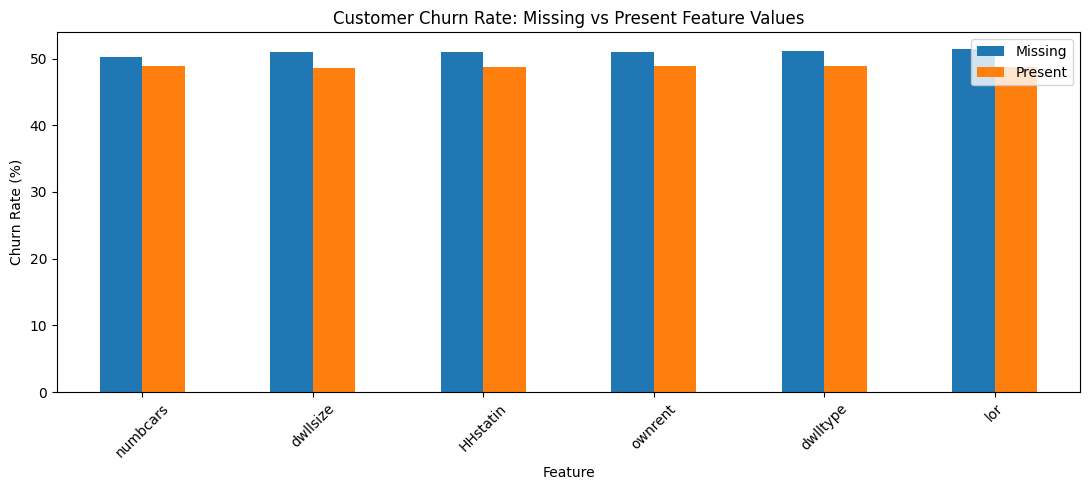

In [7]:
high_missing_cols = [
    "numbcars",
    "dwllsize",
    "HHstatin",
    "ownrent",
    "dwlltype",
    "lor"
]

results = []

for col in high_missing_cols:
    missing_mask = df[col].isna()

    churn_missing = df.loc[missing_mask, "churn"].mean()
    churn_present = df.loc[~missing_mask, "churn"].mean()

    results.append({
        "Feature": col,
        "Missing_%": missing_mask.mean() * 100,
        "Churn_when_missing_%": churn_missing * 100,
        "Churn_when_present_%": churn_present * 100,
        "Difference_pp": (
            churn_missing - churn_present
        ) * 100
    })

missing_churn_df = pd.DataFrame(results)

print("=== MISSINGNESS AND CHURN ANALYSIS ===")

display(
    missing_churn_df.sort_values(
        "Difference_pp",
        key=abs,
        ascending=False
    ).round(2)
)

# Visualize churn differences
import matplotlib.pyplot as plt

plot_df = missing_churn_df.set_index("Feature")

ax = plot_df[
    ["Churn_when_missing_%", "Churn_when_present_%"]
].plot(
    kind="bar",
    figsize=(11, 5),
    rot=45
)

plt.title("Customer Churn Rate: Missing vs Present Feature Values")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Feature")
plt.legend(["Missing", "Present"])
plt.tight_layout()
plt.show()

=== FEATURE COMPARISON BY CHURN STATUS ===


,Retained_Median,Churned_Median,Difference_%
rev_Mean,48.88,47.49,-2.84
mou_Mean,380.50,329.75,-13.34
change_mou,-3.00,-10.00,233.33
custcare_Mean,0.00,0.00,NaN
drop_vce_Mean,3.00,3.00,0.00
months,16.00,17.00,6.25
eqpdays,310.00,366.00,18.06
ovrrev_Mean,0.80,1.20,50.00


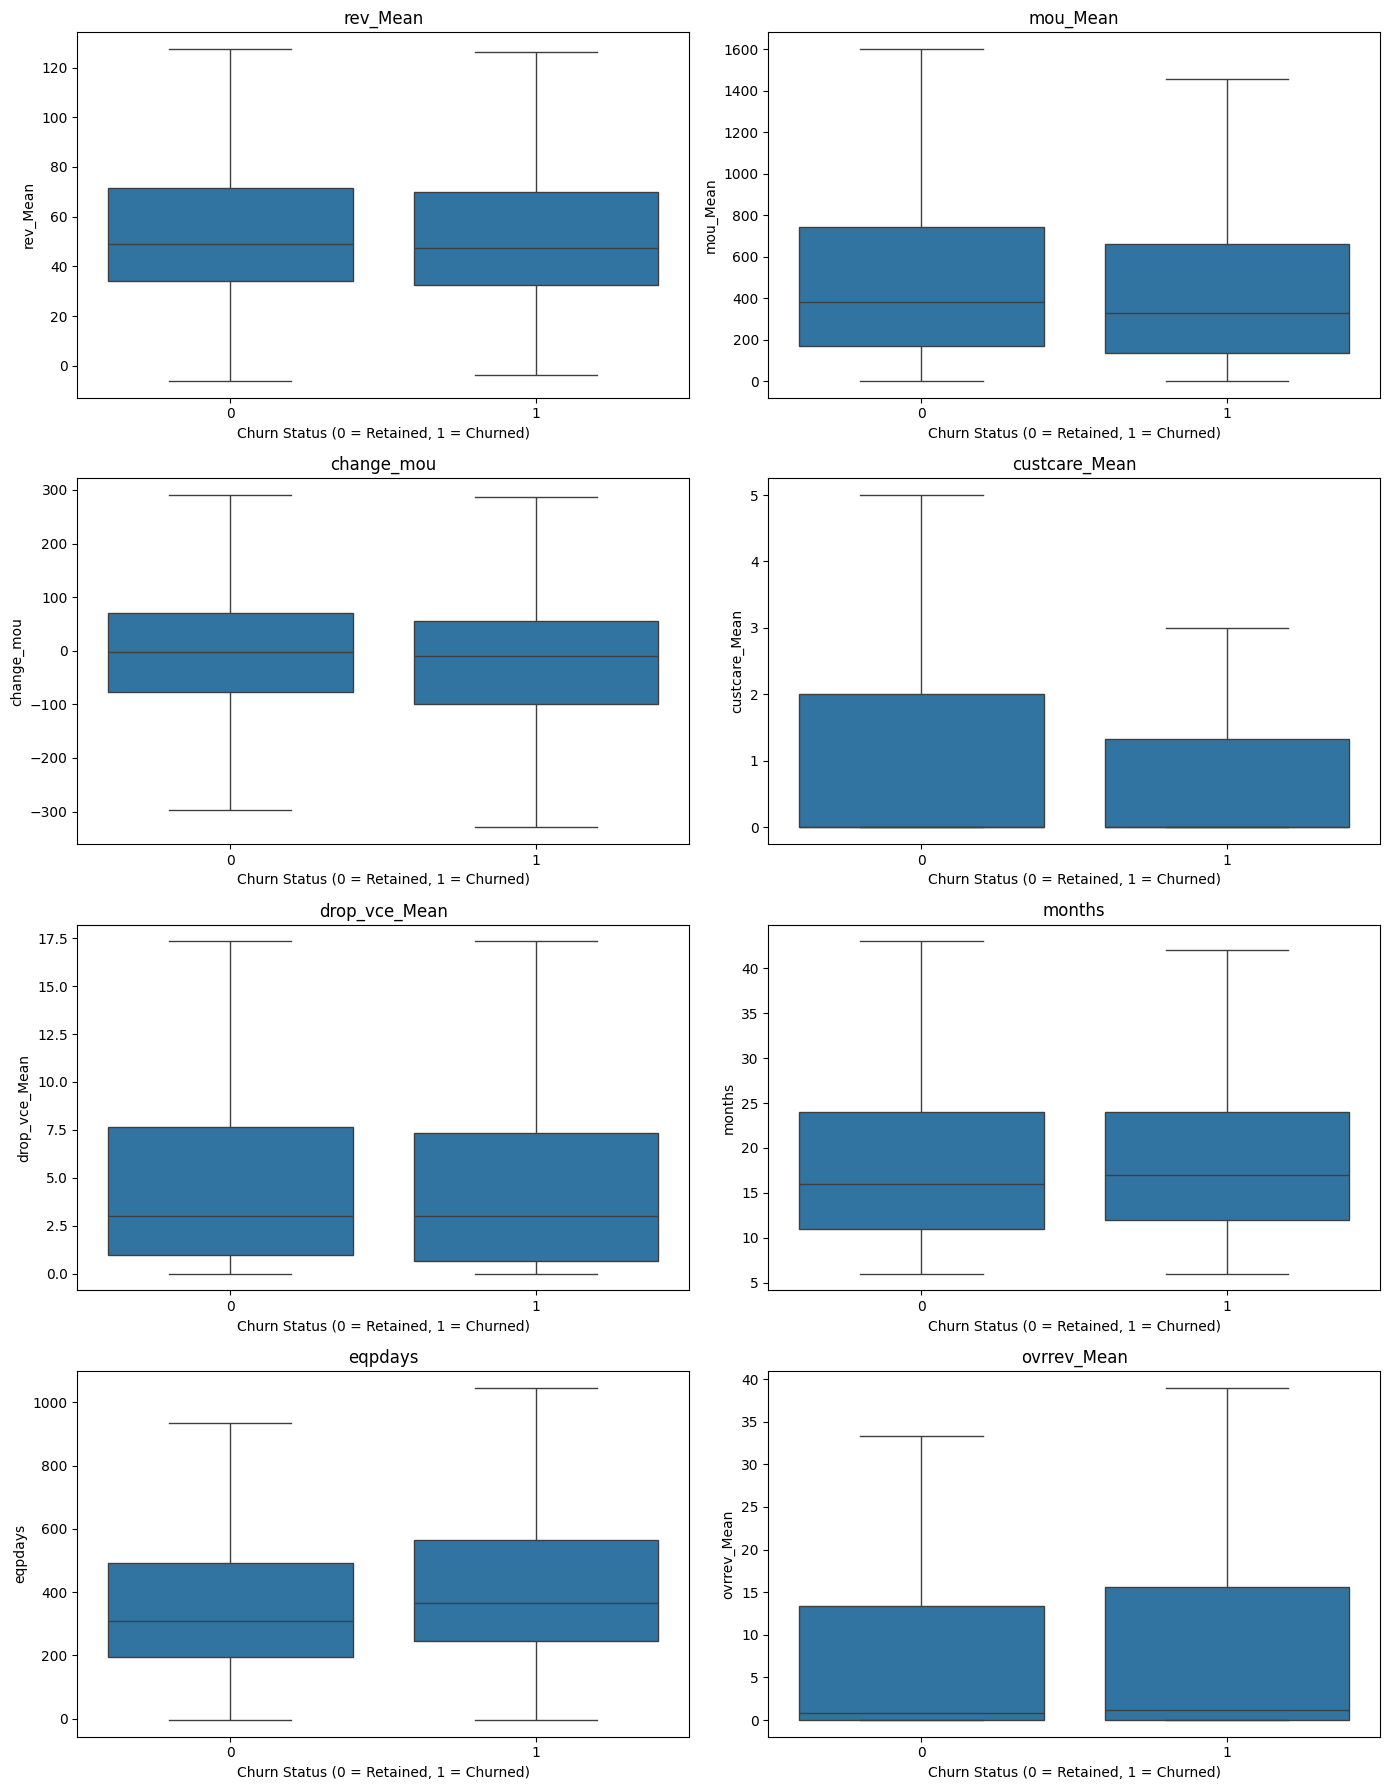

In [8]:
features = [
    "rev_Mean",
    "mou_Mean",
    "change_mou",
    "custcare_Mean",
    "drop_vce_Mean",
    "months",
    "eqpdays",
    "ovrrev_Mean"
]

# Calculate median values for each churn group
summary = df.groupby("churn")[features].median().T

summary.columns = [
    "Retained_Median",
    "Churned_Median"
]

# Calculate percentage differences
summary["Difference_%"] = (
    (summary["Churned_Median"] - summary["Retained_Median"])
    / summary["Retained_Median"].replace(0, np.nan)
) * 100

print("=== FEATURE COMPARISON BY CHURN STATUS ===")
display(summary.round(2))

# Visualize feature distributions
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for ax, feature in zip(axes.flatten(), features):

    sns.boxplot(
        data=df,
        x="churn",
        y=feature,
        ax=ax,
        showfliers=False
    )

    ax.set_title(feature)
    ax.set_xlabel("Churn Status (0 = Retained, 1 = Churned)")

plt.tight_layout()
plt.show()


=== EQPDAYS ===


,Segment,Customers,Churn_Rate
0,"(-5.001, 188.0]",20006,41.53
1,"(188.0, 300.0]",20082,37.38
2,"(300.0, 395.0]",20078,59.53
3,"(395.0, 589.0]",19868,53.04
4,"(589.0, 1823.0]",19965,56.38



=== MOU_MEAN ===


,Segment,Customers,Churn_Rate
0,"(-0.001, 115.25]",19939,55.24
1,"(115.25, 265.5]",19939,50.46
2,"(265.5, 465.0]",19913,48.62
3,"(465.0, 821.5]",19930,47.48
4,"(821.5, 12206.75]",19922,45.66



=== OVRREV_MEAN ===


,Segment,Customers,Churn_Rate
0,"(-0.001, 4.4]",59808,48.58
1,"(4.4, 20.054]",19906,49.67
2,"(20.054, 1102.4]",19929,52.06


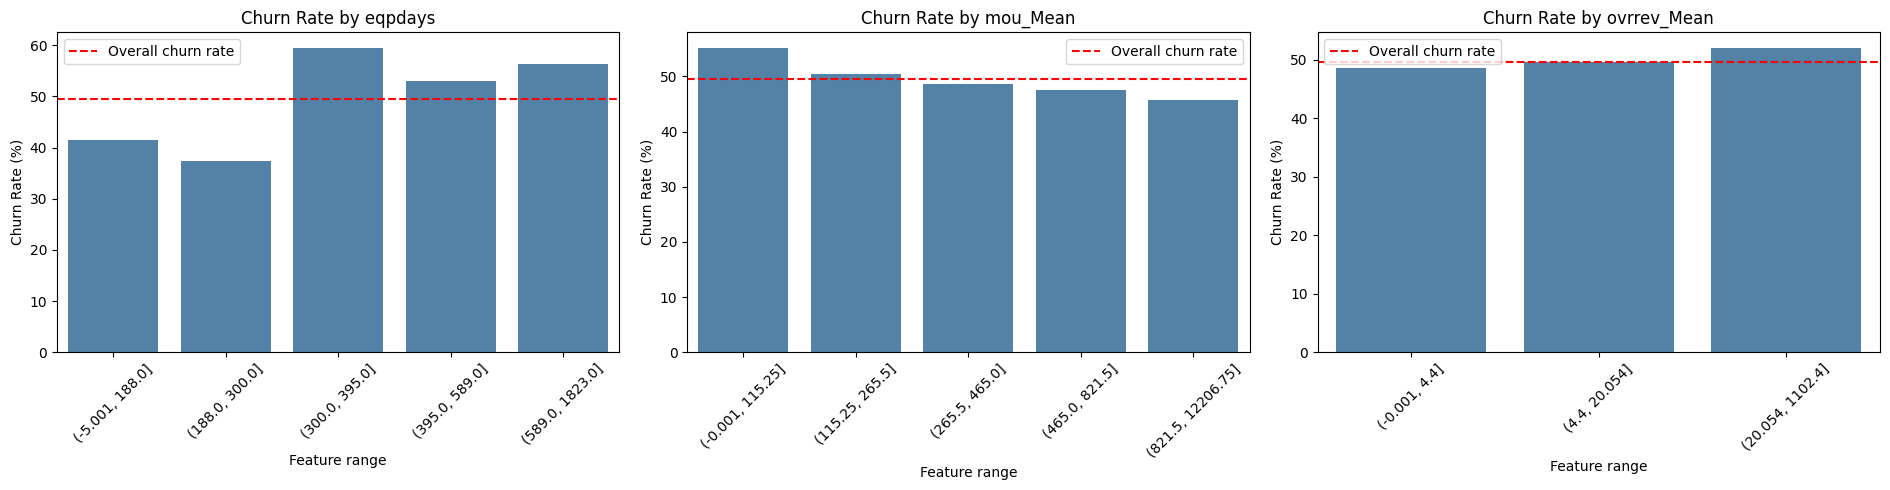

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

segment_features = [
    "eqpdays",
    "mou_Mean",
    "ovrrev_Mean"
]

segment_results = {}

for feature in segment_features:

    temp = df[[feature, "churn"]].copy()

    # Create quantile-based groups, accounting for repeated values
    temp["Segment"] = pd.qcut(
        temp[feature],
        q=5,
        duplicates="drop"
    )

    summary = (
        temp.groupby("Segment", observed=True)
        .agg(
            Customers=("churn", "size"),
            Churn_Rate=("churn", "mean")
        )
        .reset_index()
    )

    summary["Churn_Rate"] *= 100
    summary["Segment"] = summary["Segment"].astype(str)

    segment_results[feature] = summary

    print(f"\n=== {feature.upper()} ===")
    display(summary.round(2))

# Visualize segment churn rates
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, feature in zip(axes, segment_features):

    summary = segment_results[feature]

    sns.barplot(
        data=summary,
        x="Segment",
        y="Churn_Rate",
        ax=ax,
        color="steelblue"
    )

    ax.axhline(
        df["churn"].mean() * 100,
        color="red",
        linestyle="--",
        label="Overall churn rate"
    )

    ax.set_title(f"Churn Rate by {feature}")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel("Feature range")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

plt.tight_layout()
plt.show()

=== COMBINED CUSTOMER SEGMENTS ===


,Device_Age_Group,Usage_Group,Customers,Churn_Rate
0,Newer (<=300 days),Low usage,10269,39.18
1,Newer (<=300 days),Medium usage,17298,38.17
2,Newer (<=300 days),High usage,12437,41.38
3,Mid-age (301-395 days),Low usage,7894,61.84
4,Mid-age (301-395 days),Medium usage,8545,58.55
5,Mid-age (301-395 days),High usage,3616,56.75
6,Older (>395 days),Low usage,21714,56.05
7,Older (>395 days),Medium usage,14000,53.85
8,Older (>395 days),High usage,3869,49.06



=== CHURN RATE HEATMAP ===


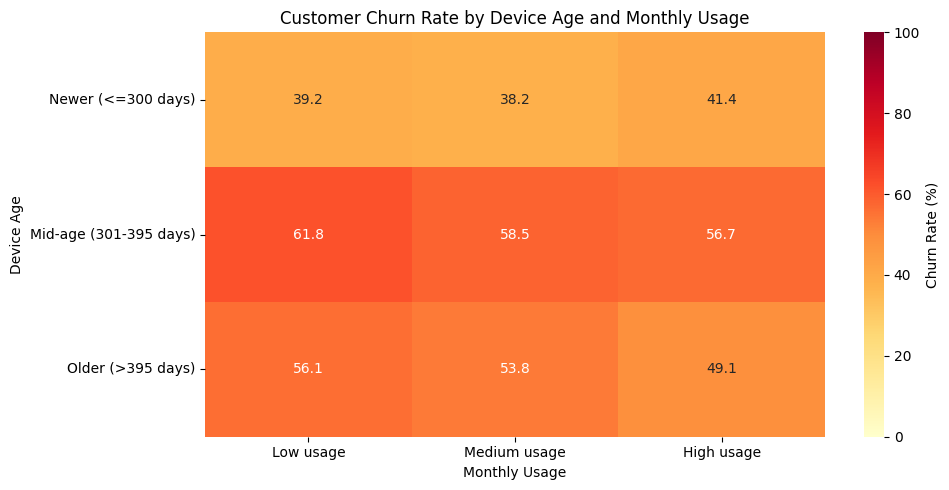


=== MISSING SEGMENT VALUES ===
Missing device age: 1
Missing monthly usage: 357
Customers included in combined analysis: 99642


In [10]:
segment_df = df[
    ["eqpdays", "mou_Mean", "churn"]
].copy()

# Device age groups
segment_df["Device_Age_Group"] = pd.cut(
    segment_df["eqpdays"],
    bins=[-float("inf"), 300, 395, float("inf")],
    labels=[
        "Newer (<=300 days)",
        "Mid-age (301-395 days)",
        "Older (>395 days)"
    ]
)

# Monthly usage groups
segment_df["Usage_Group"] = pd.cut(
    segment_df["mou_Mean"],
    bins=[-float("inf"), 265.5, 821.5, float("inf")],
    labels=[
        "Low usage",
        "Medium usage",
        "High usage"
    ]
)

# Calculate customer counts and churn rates
segment_summary = (
    segment_df.groupby(
        ["Device_Age_Group", "Usage_Group"],
        observed=True
    )
    .agg(
        Customers=("churn", "size"),
        Churn_Rate=("churn", "mean")
    )
    .reset_index()
)

segment_summary["Churn_Rate"] *= 100

print("=== COMBINED CUSTOMER SEGMENTS ===")
display(segment_summary.round(2))

# Create pivot table for visualization
churn_pivot = segment_summary.pivot(
    index="Device_Age_Group",
    columns="Usage_Group",
    values="Churn_Rate"
)

print("\n=== CHURN RATE HEATMAP ===")

plt.figure(figsize=(10, 5))

sns.heatmap(
    churn_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Churn Rate (%)"}
)

plt.title("Customer Churn Rate by Device Age and Monthly Usage")
plt.xlabel("Monthly Usage")
plt.ylabel("Device Age")

plt.tight_layout()
plt.show()

print("\n=== MISSING SEGMENT VALUES ===")
print("Missing device age:", segment_df["eqpdays"].isna().sum())
print("Missing monthly usage:", segment_df["mou_Mean"].isna().sum())
print(
    "Customers included in combined analysis:",
    segment_summary["Customers"].sum()
)

In [11]:
segment_detail = (
    segment_df.groupby(
        ["Device_Age_Group", "Usage_Group"],
        observed=True
    )
    .agg(
        Customers=("churn", "size"),
        Churned_Customers=("churn", "sum"),
        Churn_Rate=("churn", "mean")
    )
    .reset_index()
)

segment_detail["Churn_Rate_%"] = (
    segment_detail["Churn_Rate"] * 100
)

segment_detail["Share_of_All_Customers_%"] = (
    segment_detail["Customers"] / len(df) * 100
)

segment_detail["Share_of_All_Churn_%"] = (
    segment_detail["Churned_Customers"]
    / df["churn"].sum() * 100
)

print("=== SEGMENT OPPORTUNITY ANALYSIS ===")

display(
    segment_detail[
        [
            "Device_Age_Group",
            "Usage_Group",
            "Customers",
            "Churned_Customers",
            "Churn_Rate_%",
            "Share_of_All_Customers_%",
            "Share_of_All_Churn_%"
        ]
    ].sort_values(
        "Churn_Rate_%",
        ascending=False
    ).round(2)
)

print("\n=== COVERAGE CHECK ===")
print("Total customers:", len(df))
print("Customers analyzed:", segment_detail["Customers"].sum())
print("Total churn cases:", int(df["churn"].sum()))
print(
    "Churn cases in analyzed segments:",
    int(segment_detail["Churned_Customers"].sum())
)

=== SEGMENT OPPORTUNITY ANALYSIS ===


,Device_Age_Group,Usage_Group,Customers,Churned_Customers,Churn_Rate_%,Share_of_All_Customers_%,Share_of_All_Churn_%
3,Mid-age (301-395 days),Low usage,7894,4882,61.84,7.89,9.85
4,Mid-age (301-395 days),Medium usage,8545,5003,58.55,8.54,10.09
5,Mid-age (301-395 days),High usage,3616,2052,56.75,3.62,4.14
6,Older (>395 days),Low usage,21714,12171,56.05,21.71,24.56
7,Older (>395 days),Medium usage,14000,7539,53.85,14.00,15.21
8,Older (>395 days),High usage,3869,1898,49.06,3.87,3.83
2,Newer (<=300 days),High usage,12437,5147,41.38,12.44,10.38
0,Newer (<=300 days),Low usage,10269,4023,39.18,10.27,8.12
1,Newer (<=300 days),Medium usage,17298,6602,38.17,17.30,13.32



=== COVERAGE CHECK ===
Total customers: 100000
Customers analyzed: 99642
Total churn cases: 49562
Churn cases in analyzed segments: 49317


In [12]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Separate features and target
X = df.drop(columns=["churn", "Customer_ID"])
y = df["churn"].astype(int)

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("=== DATASET SPLIT ===")

for name, features, target in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(f"\n{name}:")
    print("Shape:", features.shape)
    print("Churn rate:", round(target.mean() * 100, 2), "%")
    print("Churned customers:", int(target.sum()))
    print("Retained customers:", int((target == 0).sum()))

print("\n=== LEAKAGE CHECK ===")

train_ids = set(X_train.index)
val_ids = set(X_val.index)
test_ids = set(X_test.index)

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(X_train) + len(X_val) + len(X_test) == len(df)
assert "churn" not in X_train.columns
assert "Customer_ID" not in X_train.columns

print("No overlapping rows between splits.")
print("Target and customer identifier excluded from features.")
print("All split validation checks passed!")

=== DATASET SPLIT ===

Training:
Shape: (70000, 98)
Churn rate: 49.56 %
Churned customers: 34693
Retained customers: 35307

Validation:
Shape: (15000, 98)
Churn rate: 49.57 %
Churned customers: 7435
Retained customers: 7565

Test:
Shape: (15000, 98)
Churn rate: 49.56 %
Churned customers: 7434
Retained customers: 7566

=== LEAKAGE CHECK ===
No overlapping rows between splits.
Target and customer identifier excluded from features.
All split validation checks passed!


In [13]:
# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("=== FEATURE TYPES ===")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", X_train.shape[1])

# Check infinity values in numerical columns
numeric_train = X_train[numeric_features]

infinity_counts = np.isinf(
    numeric_train.to_numpy(dtype="float64")
).sum(axis=0)

infinity_summary = pd.Series(
    infinity_counts,
    index=numeric_features
)

print("\n=== INFINITY VALUES ===")
print("Total infinity values:", int(infinity_summary.sum()))
print(infinity_summary[infinity_summary > 0])

# Check completely missing numerical features
all_missing_numeric = [
    col for col in numeric_features
    if X_train[col].isna().all()
]

print("\n=== COMPLETELY MISSING NUMERICAL FEATURES ===")
print(all_missing_numeric)

# Examine categorical cardinality and missingness
categorical_summary = pd.DataFrame({
    "Unique_Categories": X_train[
        categorical_features
    ].nunique(dropna=True),
    "Missing_Percent": X_train[
        categorical_features
    ].isna().mean() * 100
}).sort_values(
    "Unique_Categories",
    ascending=False
)

print("\n=== CATEGORICAL FEATURE SUMMARY ===")
display(categorical_summary.round(2))

# Check training-set feature coverage
print("\n=== FEATURE VALIDATION ===")
print("Total columns accounted for:",
      len(numeric_features) + len(categorical_features))

print("All features accounted for:",
      len(numeric_features) + len(categorical_features)
      == X_train.shape[1])

=== FEATURE TYPES ===
Numerical features: 77
Categorical features: 21
Total features: 98

=== INFINITY VALUES ===
Total infinity values: 0
Series([], dtype: int64)

=== COMPLETELY MISSING NUMERICAL FEATURES ===
[]

=== CATEGORICAL FEATURE SUMMARY ===


,Unique_Categories,Missing_Percent
crclscod,53,0.00
area,19,0.04
ethnic,17,1.75
dwllsize,15,38.38
HHstatin,6,37.89
prizm_social_one,5,7.41
marital,5,1.75
dualband,4,0.00
new_cell,3,0.00
hnd_webcap,3,10.15



=== FEATURE VALIDATION ===
Total columns accounted for: 98
All features accounted for: True


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    )
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        )
    )
])

# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0.3
)

# Fit ONLY on training data
print("=== FITTING PREPROCESSOR ===")

X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("\n=== PROCESSED DATASET SHAPES ===")
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

# Check feature consistency
assert (
    X_train_processed.shape[1]
    == X_val_processed.shape[1]
    == X_test_processed.shape[1]
)

# Check invalid values
import numpy as np
from scipy import sparse

def count_invalid_values(matrix):
    values = matrix.data if sparse.issparse(matrix) else matrix
    return int((~np.isfinite(values)).sum())

print("\n=== INVALID VALUE CHECK ===")
print("Training:", count_invalid_values(X_train_processed))
print("Validation:", count_invalid_values(X_val_processed))
print("Test:", count_invalid_values(X_test_processed))

print("\n=== PREPROCESSING COMPLETE ===")
print("All datasets have consistent feature dimensions.")

=== FITTING PREPROCESSOR ===

=== PROCESSED DATASET SHAPES ===
Training: (70000, 272)
Validation: (15000, 272)
Test: (15000, 272)

=== INVALID VALUE CHECK ===
Training: 0
Validation: 0
Test: 0

=== PREPROCESSING COMPLETE ===
All datasets have consistent feature dimensions.


In [15]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import time

print("=== TRAINING BASELINE MODEL ===")

# Scaling is useful for Logistic Regression.
# with_mean=False supports sparse matrices.
baseline_model = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("model", LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        random_state=42
    ))
])

start_time = time.time()

baseline_model.fit(X_train_processed, y_train)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds")

# Validation predictions
y_val_pred = baseline_model.predict(X_val_processed)
y_val_proba = baseline_model.predict_proba(
    X_val_processed
)[:, 1]

# Evaluation
baseline_results = {
    "Model": "Logistic Regression",
    "ROC_AUC": roc_auc_score(y_val, y_val_proba),
    "PR_AUC": average_precision_score(y_val, y_val_proba),
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(y_val, y_val_pred),
    "Recall": recall_score(y_val, y_val_pred),
    "F1": f1_score(y_val, y_val_pred),
    "Training_Time_Seconds": training_time
}

print("\n=== BASELINE VALIDATION RESULTS ===")

display(
    pd.DataFrame([baseline_results]).round(4)
)

print("\n=== MODEL CONVERGENCE ===")
print(
    "Iterations:",
    baseline_model.named_steps["model"].n_iter_
)

=== TRAINING BASELINE MODEL ===
Training completed in 12.12 seconds

=== BASELINE VALIDATION RESULTS ===


,Model,ROC_AUC,PR_AUC,Accuracy,Precision,Recall,F1,Training_Time_Seconds
0,Logistic Regression,0.6328,0.6081,0.5971,0.5942,0.5906,0.5924,12.1226



=== MODEL CONVERGENCE ===
Iterations: [255]


In [16]:
import xgboost as xgb
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=== XGBOOST ENVIRONMENT ===")
print("XGBoost version:", xgb.__version__)

# Configure GPU-accelerated XGBoost
xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    device="cuda:0",
    random_state=42,
    n_jobs=4
)

print("\n=== TRAINING XGBOOST ON GPU ===")

start_time = time.time()

xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

xgb_training_time = time.time() - start_time

print(f"Training completed in {xgb_training_time:.2f} seconds")

# Check GPU configuration
print("\n=== MODEL GPU CONFIGURATION ===")

config = xgb_model.get_booster().save_config()

import json

config_dict = json.loads(config)

actual_device = config_dict["learner"]["generic_param"]["device"]

print("Configured training device:", actual_device)

if actual_device.startswith("cuda"):
    print("GPU configuration verified.")
else:
    print("WARNING: Model is not configured to use GPU!")

# Validation predictions
xgb_val_proba = xgb_model.predict_proba(
    X_val_processed
)[:, 1]

xgb_val_pred = (xgb_val_proba >= 0.5).astype(int)

# Evaluation metrics
xgb_results = {
    "Model": "XGBoost GPU",
    "ROC_AUC": roc_auc_score(y_val, xgb_val_proba),
    "PR_AUC": average_precision_score(y_val, xgb_val_proba),
    "Accuracy": accuracy_score(y_val, xgb_val_pred),
    "Precision": precision_score(y_val, xgb_val_pred),
    "Recall": recall_score(y_val, xgb_val_pred),
    "F1": f1_score(y_val, xgb_val_pred),
    "Training_Time_Seconds": xgb_training_time
}

print("\n=== XGBOOST VALIDATION RESULTS ===")
display(pd.DataFrame([xgb_results]).round(4))

print("\n=== BASELINE VS XGBOOST ===")

comparison_df = pd.DataFrame([
    baseline_results,
    xgb_results
])

display(comparison_df.round(4))

=== XGBOOST ENVIRONMENT ===
XGBoost version: 3.4.1

=== TRAINING XGBOOST ON GPU ===
Training completed in 3.63 seconds

=== MODEL GPU CONFIGURATION ===
Configured training device: cuda:0
GPU configuration verified.

=== XGBOOST VALIDATION RESULTS ===


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [16:25:23] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


,Model,ROC_AUC,PR_AUC,Accuracy,Precision,Recall,F1,Training_Time_Seconds
0,XGBoost GPU,0.7013,0.6914,0.6419,0.6362,0.6483,0.6422,3.6263



=== BASELINE VS XGBOOST ===


,Model,ROC_AUC,PR_AUC,Accuracy,Precision,Recall,F1,Training_Time_Seconds
0,Logistic Regression,0.6328,0.6081,0.5971,0.5942,0.5906,0.5924,12.1226
1,XGBoost GPU,0.7013,0.6914,0.6419,0.6362,0.6483,0.6422,3.6263


=== AVAILABLE EVALUATION HISTORY ===
dict_keys(['validation_0'])

=== TRAINING ANALYSIS ===
Total boosting rounds: 500
Best iteration: 493
Best validation ROC-AUC: 0.70147
Final validation ROC-AUC: 0.70133
Difference: 0.00014


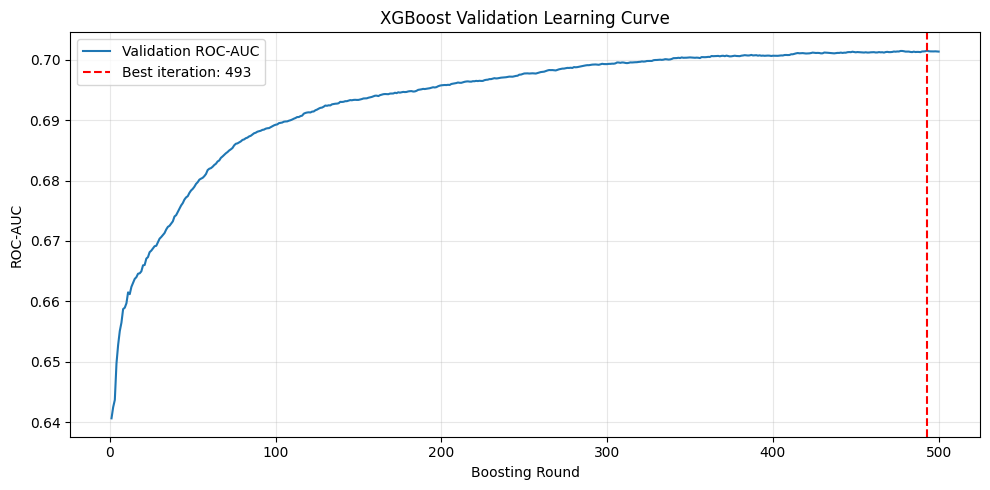


=== SELECTED BOOSTING ROUNDS ===


,Round,Validation_ROC_AUC
0,50,0.67861
1,100,0.68923
2,200,0.69575
3,300,0.69926
4,400,0.70065
5,493,0.70147
6,500,0.70133


In [17]:
# Retrieve evaluation history
eval_history = xgb_model.evals_result()

print("=== AVAILABLE EVALUATION HISTORY ===")
print(eval_history.keys())

# Validation ROC-AUC across boosting rounds
val_auc = np.array(
    eval_history["validation_0"]["auc"]
)

best_iteration = int(np.argmax(val_auc)) + 1
best_auc = float(np.max(val_auc))
final_auc = float(val_auc[-1])

print("\n=== TRAINING ANALYSIS ===")
print("Total boosting rounds:", len(val_auc))
print("Best iteration:", best_iteration)
print("Best validation ROC-AUC:", round(best_auc, 5))
print("Final validation ROC-AUC:", round(final_auc, 5))
print("Difference:", round(best_auc - final_auc, 5))

# Plot validation performance
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(val_auc) + 1),
    val_auc,
    label="Validation ROC-AUC"
)

plt.axvline(
    best_iteration,
    color="red",
    linestyle="--",
    label=f"Best iteration: {best_iteration}"
)

plt.xlabel("Boosting Round")
plt.ylabel("ROC-AUC")
plt.title("XGBoost Validation Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display performance at selected rounds
selected_rounds = sorted(set(
    [50, 100, 200, 300, 400, 500, best_iteration]
))

round_summary = pd.DataFrame([
    {
        "Round": r,
        "Validation_ROC_AUC": val_auc[r - 1]
    }
    for r in selected_rounds
    if r <= len(val_auc)
])

print("\n=== SELECTED BOOSTING ROUNDS ===")
display(round_summary.round(5))

In [18]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


print("=== TRAINING IMPROVED XGBOOST ===")

xgb_tuned = XGBClassifier(
    n_estimators=1500,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    device="cuda:0",
    early_stopping_rounds=75,
    random_state=42,
    n_jobs=4
)

start_time = time.time()

xgb_tuned.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

tuned_training_time = time.time() - start_time

print(f"Training time: {tuned_training_time:.2f} seconds")

# Verify GPU device
config = json.loads(xgb_tuned.get_booster().save_config())
device = config["learner"]["generic_param"]["device"]

print("\n=== GPU VERIFICATION ===")
print("Training device:", device)

# Early stopping results
print("\n=== EARLY STOPPING RESULTS ===")
print("Best iteration:", xgb_tuned.best_iteration)
print("Best validation score:", xgb_tuned.best_score)
print("Trees built:", xgb_tuned.get_booster().num_boosted_rounds())

# Validation predictions
tuned_val_proba = xgb_tuned.predict_proba(
    X_val_processed
)[:, 1]

tuned_val_pred = (
    tuned_val_proba >= 0.5
).astype(int)

# Evaluation
tuned_results = {
    "Model": "XGBoost Tuned GPU",
    "ROC_AUC": roc_auc_score(y_val, tuned_val_proba),
    "PR_AUC": average_precision_score(y_val, tuned_val_proba),
    "Accuracy": accuracy_score(y_val, tuned_val_pred),
    "Precision": precision_score(y_val, tuned_val_pred),
    "Recall": recall_score(y_val, tuned_val_pred),
    "F1": f1_score(y_val, tuned_val_pred),
    "Training_Time_Seconds": tuned_training_time
}

print("\n=== TUNED MODEL RESULTS ===")
display(pd.DataFrame([tuned_results]).round(4))

# Compare three models
print("\n=== MODEL COMPARISON ===")

comparison_all = pd.DataFrame([
    baseline_results,
    xgb_results,
    tuned_results
])

display(
    comparison_all.sort_values(
        "ROC_AUC",
        ascending=False
    ).round(4)
)

=== TRAINING IMPROVED XGBOOST ===
Training time: 5.89 seconds

=== GPU VERIFICATION ===
Training device: cuda:0

=== EARLY STOPPING RESULTS ===
Best iteration: 959
Best validation score: 0.7031848525511472
Trees built: 1035

=== TUNED MODEL RESULTS ===


,Model,ROC_AUC,PR_AUC,Accuracy,Precision,Recall,F1,Training_Time_Seconds
0,XGBoost Tuned GPU,0.7032,0.6923,0.6419,0.6372,0.6443,0.6407,5.8865



=== MODEL COMPARISON ===


,Model,ROC_AUC,PR_AUC,Accuracy,Precision,Recall,F1,Training_Time_Seconds
2,XGBoost Tuned GPU,0.7032,0.6923,0.6419,0.6372,0.6443,0.6407,5.8865
1,XGBoost GPU,0.7013,0.6914,0.6419,0.6362,0.6483,0.6422,3.6263
0,Logistic Regression,0.6328,0.6081,0.5971,0.5942,0.5906,0.5924,12.1226


=== TOP 20 IMPORTANT FEATURES ===


,Feature,Total_Gain,Importance_%
27,num__eqpdays,34721.152,8.603
76,num__months,22979.479,5.693
37,num__change_mou,18357.193,4.548
29,num__mou_Mean,14840.723,3.677
30,num__totmrc_Mean,13679.313,3.389
38,num__change_rev,11771.570,2.917
10,num__avgqty,8884.300,2.201
8,num__avgrev,8034.145,1.991
17,num__hnd_price,7941.490,1.968
9,num__avgmou,7513.969,1.862



=== FEATURE IMPORTANCE CHECK ===
Total features: 272
Total importance (%): 100.0


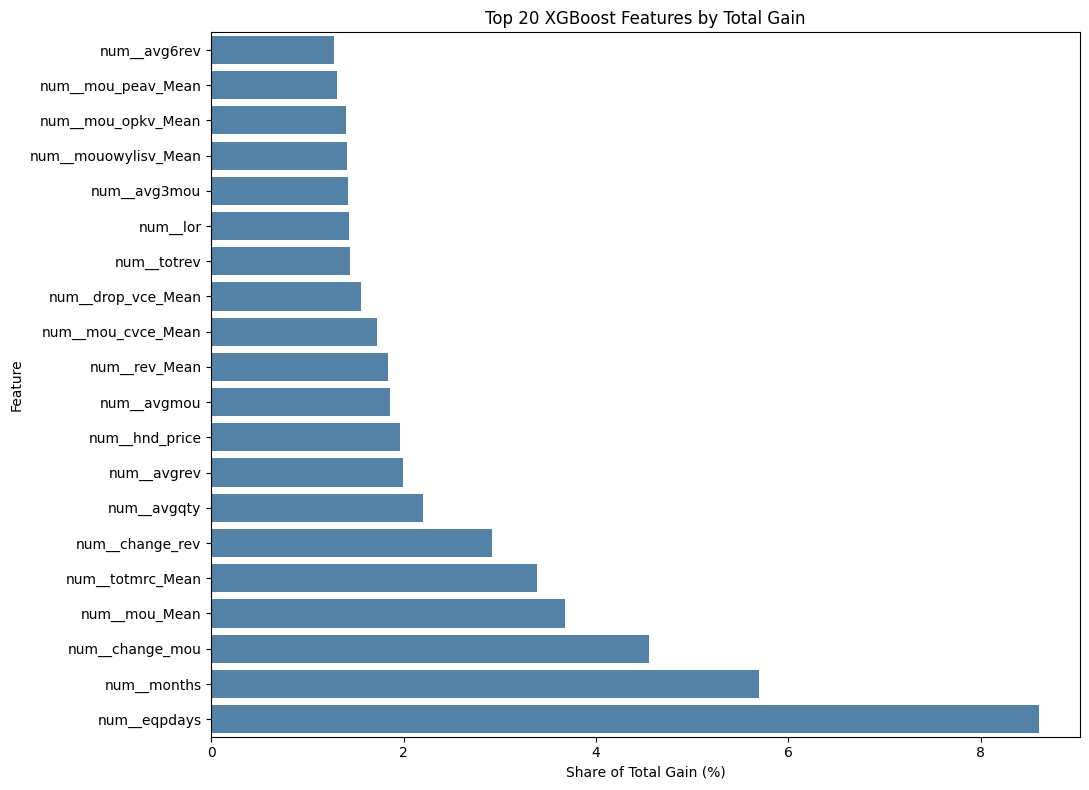

In [19]:
# Retrieve feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Retrieve total gain importance from XGBoost
booster = xgb_tuned.get_booster()
gain_scores = booster.get_score(importance_type="total_gain")

# Match XGBoost feature indices with actual names
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Total_Gain": [
        gain_scores.get(f"f{i}", 0.0)
        for i in range(len(feature_names))
    ]
})

# Convert to relative percentage
total_gain = importance_df["Total_Gain"].sum()

importance_df["Importance_%"] = (
    importance_df["Total_Gain"] / total_gain * 100
)

importance_df = importance_df.sort_values(
    "Total_Gain",
    ascending=False
)

print("=== TOP 20 IMPORTANT FEATURES ===")

display(
    importance_df.head(20).round(3)
)

print("\n=== FEATURE IMPORTANCE CHECK ===")
print("Total features:", len(importance_df))
print(
    "Total importance (%):",
    round(importance_df["Importance_%"].sum(), 2)
)

# Plot the top 20 features
top_features = importance_df.head(20).sort_values(
    "Importance_%"
)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_features,
    x="Importance_%",
    y="Feature",
    color="steelblue"
)

plt.title("Top 20 XGBoost Features by Total Gain")
plt.xlabel("Share of Total Gain (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

=== HIGH-RISK CUSTOMER TARGETING ===


,Top_Risk_%,Customers_Targeted,Actual_Churners_Captured,Churn_Rate_%,Recall_%,Lift
0,5,750,638,85.067,8.581,1.716
1,10,1500,1201,80.067,16.153,1.615
2,20,3000,2243,74.767,30.168,1.508
3,30,4500,3153,70.067,42.408,1.414



=== VALIDATION BASELINE ===
Total customers: 15000
Total churners: 7435
Overall churn rate: 49.57 %


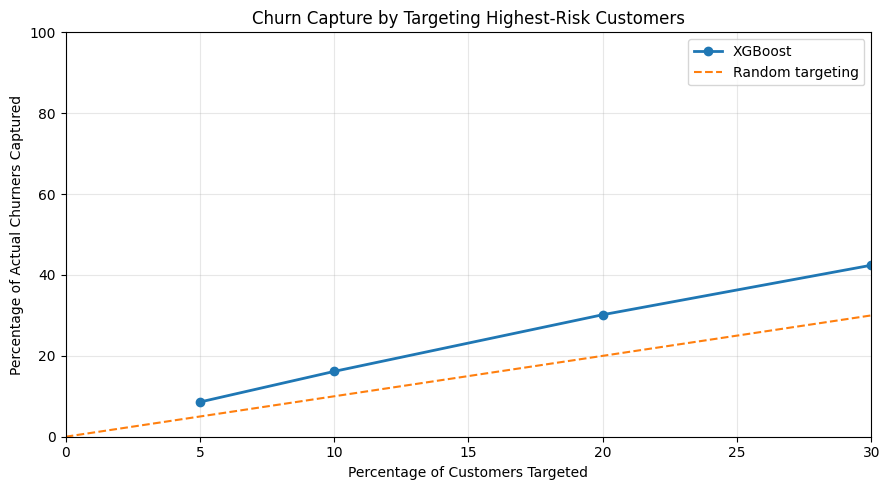

In [20]:
# Use validation predictions from tuned XGBoost
targeting_df = pd.DataFrame({
    "Actual_Churn": y_val.to_numpy(),
    "Predicted_Probability": tuned_val_proba
})

# Rank customers from highest to lowest predicted risk
targeting_df = targeting_df.sort_values(
    "Predicted_Probability",
    ascending=False
).reset_index(drop=True)

total_customers = len(targeting_df)
total_churners = targeting_df["Actual_Churn"].sum()
overall_churn_rate = targeting_df["Actual_Churn"].mean()

targeting_results = []

for pct in [5, 10, 20, 30]:
    n_customers = int(total_customers * pct / 100)

    top_group = targeting_df.head(n_customers)

    captured_churners = int(
        top_group["Actual_Churn"].sum()
    )

    group_churn_rate = top_group["Actual_Churn"].mean()

    targeting_results.append({
        "Top_Risk_%": pct,
        "Customers_Targeted": n_customers,
        "Actual_Churners_Captured": captured_churners,
        "Churn_Rate_%": group_churn_rate * 100,
        "Recall_%": captured_churners / total_churners * 100,
        "Lift": group_churn_rate / overall_churn_rate
    })

targeting_summary = pd.DataFrame(targeting_results)

print("=== HIGH-RISK CUSTOMER TARGETING ===")
display(targeting_summary.round(3))

print("\n=== VALIDATION BASELINE ===")
print("Total customers:", total_customers)
print("Total churners:", total_churners)
print(
    "Overall churn rate:",
    round(overall_churn_rate * 100, 2), "%"
)

# Visualization
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    targeting_summary["Top_Risk_%"],
    targeting_summary["Recall_%"],
    marker="o",
    linewidth=2,
    label="XGBoost"
)

ax.plot(
    [0, 30],
    [0, 30],
    linestyle="--",
    label="Random targeting"
)

ax.set_title("Churn Capture by Targeting Highest-Risk Customers")
ax.set_xlabel("Percentage of Customers Targeted")
ax.set_ylabel("Percentage of Actual Churners Captured")
ax.set_xlim(0, 30)
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

=== PROBABILITY CALIBRATION METRICS ===
Brier score: 0.21809
Log loss: 0.62484
Constant baseline Brier score: 0.24998

=== CALIBRATION BY RISK GROUP ===


,Mean_Predicted_Probability,Observed_Churn_Rate,Difference_pp
0,0.1896,0.1773,-1.2221
1,0.2987,0.3013,0.2679
2,0.3726,0.3700,-0.2606
3,0.4297,0.4153,-1.4379
4,0.4778,0.5067,2.8843
5,0.5242,0.5167,-0.7507
6,0.5700,0.5673,-0.2619
7,0.6191,0.6067,-1.2445
8,0.6806,0.6947,1.4081
9,0.7952,0.8007,0.5462


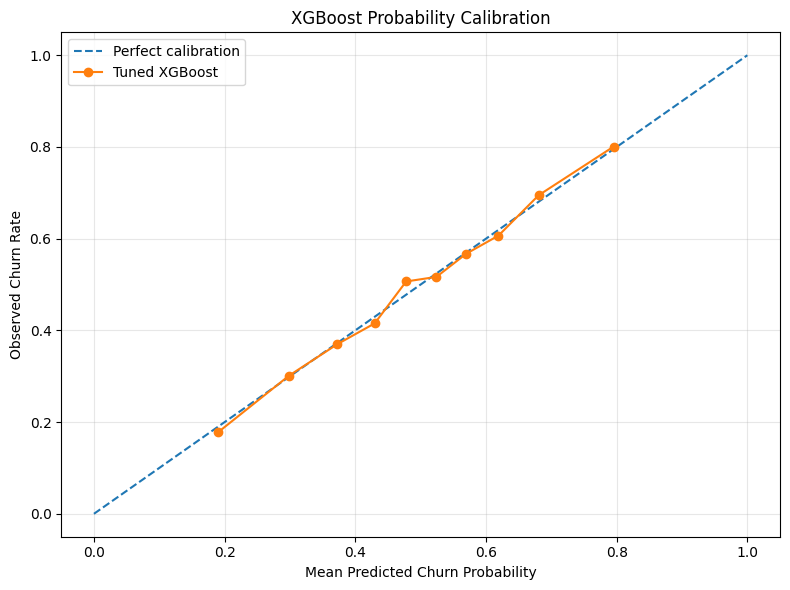

In [21]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

print("=== PROBABILITY CALIBRATION METRICS ===")

brier = brier_score_loss(y_val, tuned_val_proba)
logloss = log_loss(y_val, tuned_val_proba)

print("Brier score:", round(brier, 5))
print("Log loss:", round(logloss, 5))

# Compare against constant-prevalence predictions
baseline_probability = y_train.mean()

constant_predictions = np.full(
    len(y_val),
    baseline_probability
)

baseline_brier = brier_score_loss(
    y_val,
    constant_predictions
)

print("Constant baseline Brier score:",
      round(baseline_brier, 5))

# Calibration curve
fraction_of_positives, mean_predicted_value = (
    calibration_curve(
        y_val,
        tuned_val_proba,
        n_bins=10,
        strategy="quantile"
    )
)

calibration_df = pd.DataFrame({
    "Mean_Predicted_Probability": mean_predicted_value,
    "Observed_Churn_Rate": fraction_of_positives
})

calibration_df["Difference_pp"] = (
    calibration_df["Observed_Churn_Rate"]
    - calibration_df["Mean_Predicted_Probability"]
) * 100

print("\n=== CALIBRATION BY RISK GROUP ===")
display(calibration_df.round(4))

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label="Tuned XGBoost"
)

plt.xlabel("Mean Predicted Churn Probability")
plt.ylabel("Observed Churn Rate")
plt.title("XGBoost Probability Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

=== FINAL TEST SET EVALUATION ===

=== FINAL TEST METRICS ===


,Model,ROC_AUC,PR_AUC,Accuracy,Precision,Recall,F1,Brier_Score
0,Tuned XGBoost GPU,0.6945,0.6816,0.6401,0.634,0.6476,0.6407,0.2206



=== VALIDATION VS TEST ===


,Dataset,ROC_AUC,PR_AUC,Accuracy,Precision,Recall,F1
0,Validation,0.7032,0.6923,0.6419,0.6372,0.6443,0.6407
1,Test,0.6945,0.6816,0.6401,0.6340,0.6476,0.6407



=== CONFUSION MATRIX ===
[[4787 2779]
 [2620 4814]]


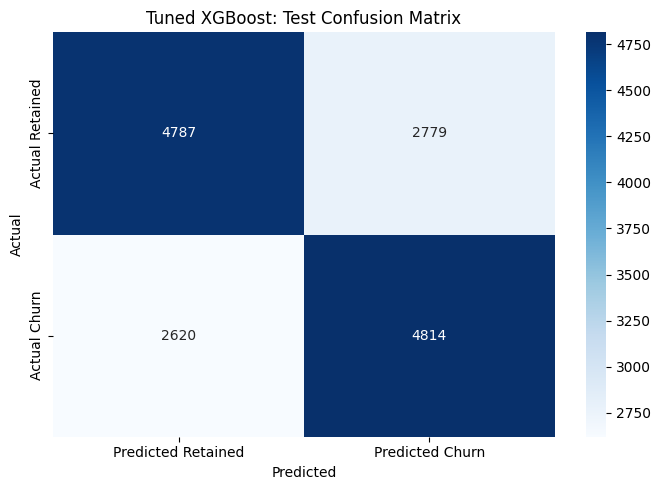


=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Retained       0.65      0.63      0.64      7566
     Churned       0.63      0.65      0.64      7434

    accuracy                           0.64     15000
   macro avg       0.64      0.64      0.64     15000
weighted avg       0.64      0.64      0.64     15000



In [22]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    brier_score_loss
)

print("=== FINAL TEST SET EVALUATION ===")

# Predictions using selected tuned XGBoost model
test_proba = xgb_tuned.predict_proba(
    X_test_processed
)[:, 1]

test_pred = (test_proba >= 0.5).astype(int)

# Calculate evaluation metrics
final_test_results = {
    "Model": "Tuned XGBoost GPU",
    "ROC_AUC": roc_auc_score(y_test, test_proba),
    "PR_AUC": average_precision_score(y_test, test_proba),
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred),
    "Recall": recall_score(y_test, test_pred),
    "F1": f1_score(y_test, test_pred),
    "Brier_Score": brier_score_loss(y_test, test_proba)
}

print("\n=== FINAL TEST METRICS ===")
display(pd.DataFrame([final_test_results]).round(4))

# Compare validation and test performance
comparison = pd.DataFrame([
    {
        "Dataset": "Validation",
        "ROC_AUC": tuned_results["ROC_AUC"],
        "PR_AUC": tuned_results["PR_AUC"],
        "Accuracy": tuned_results["Accuracy"],
        "Precision": tuned_results["Precision"],
        "Recall": tuned_results["Recall"],
        "F1": tuned_results["F1"]
    },
    {
        "Dataset": "Test",
        "ROC_AUC": final_test_results["ROC_AUC"],
        "PR_AUC": final_test_results["PR_AUC"],
        "Accuracy": final_test_results["Accuracy"],
        "Precision": final_test_results["Precision"],
        "Recall": final_test_results["Recall"],
        "F1": final_test_results["F1"]
    }
])

print("\n=== VALIDATION VS TEST ===")
display(comparison.round(4))

# Confusion matrix
cm = confusion_matrix(y_test, test_pred)

print("\n=== CONFUSION MATRIX ===")
print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Retained", "Predicted Churn"],
    yticklabels=["Actual Retained", "Actual Churn"]
)

plt.title("Tuned XGBoost: Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

print("\n=== CLASSIFICATION REPORT ===")
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["Retained", "Churned"]
    )
)

=== FINAL TEST TARGETING RESULTS ===


,Top_Risk_%,Customers_Targeted,Churners_Captured,Churn_Rate_%,Recall_%,Lift
0,5,750,638,85.067,8.582,1.716
1,10,1500,1193,79.533,16.048,1.605
2,20,3000,2191,73.033,29.473,1.474
3,30,4500,3102,68.933,41.727,1.391



=== TEST DATA BASELINE ===
Customers: 15000
Churners: 7434
Churn rate: 49.56 %


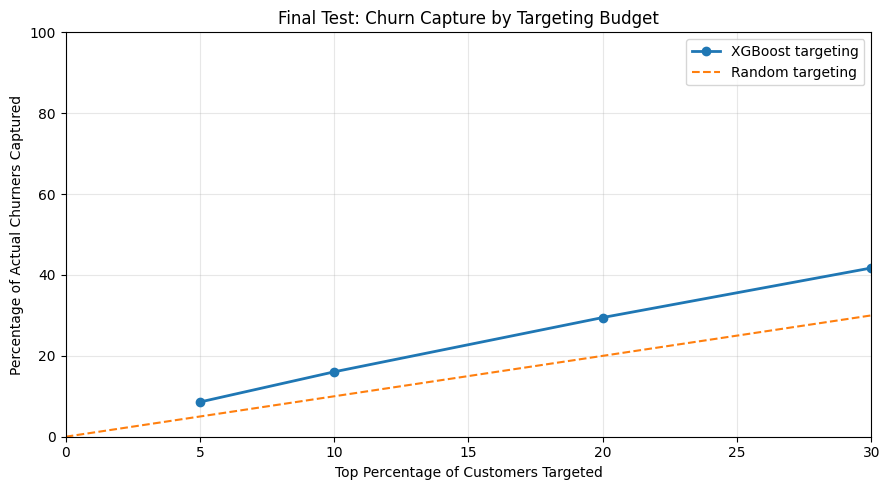

In [23]:
test_targeting_df = pd.DataFrame({
    "Actual_Churn": y_test.to_numpy(),
    "Predicted_Probability": test_proba
})

# Sort from highest to lowest churn probability
test_targeting_df = test_targeting_df.sort_values(
    "Predicted_Probability",
    ascending=False
).reset_index(drop=True)

total_test_customers = len(test_targeting_df)
total_test_churners = int(test_targeting_df["Actual_Churn"].sum())
test_churn_rate = test_targeting_df["Actual_Churn"].mean()

test_targeting_results = []

for pct in [5, 10, 20, 30]:
    n = int(total_test_customers * pct / 100)

    top_group = test_targeting_df.head(n)

    captured = int(top_group["Actual_Churn"].sum())
    group_rate = top_group["Actual_Churn"].mean()

    test_targeting_results.append({
        "Top_Risk_%": pct,
        "Customers_Targeted": n,
        "Churners_Captured": captured,
        "Churn_Rate_%": group_rate * 100,
        "Recall_%": captured / total_test_churners * 100,
        "Lift": group_rate / test_churn_rate
    })

test_targeting_summary = pd.DataFrame(
    test_targeting_results
)

print("=== FINAL TEST TARGETING RESULTS ===")
display(test_targeting_summary.round(3))

print("\n=== TEST DATA BASELINE ===")
print("Customers:", total_test_customers)
print("Churners:", total_test_churners)
print("Churn rate:", round(test_churn_rate * 100, 2), "%")

# Targeting performance visualization
plt.figure(figsize=(9, 5))

plt.plot(
    test_targeting_summary["Top_Risk_%"],
    test_targeting_summary["Recall_%"],
    marker="o",
    linewidth=2,
    label="XGBoost targeting"
)

plt.plot(
    [0, 30],
    [0, 30],
    linestyle="--",
    label="Random targeting"
)

plt.title("Final Test: Churn Capture by Targeting Budget")
plt.xlabel("Top Percentage of Customers Targeted")
plt.ylabel("Percentage of Actual Churners Captured")
plt.xlim(0, 30)
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# Use the untouched test-set predictions already generated
revenue_df = X_test[
    ["rev_Mean", "avgrev"]
].copy()

revenue_df["Actual_Churn"] = y_test
revenue_df["Predicted_Probability"] = test_proba

# Revenue validation
print("=== REVENUE DATA QUALITY ===")

for col in ["rev_Mean", "avgrev"]:
    print(f"\n{col}:")
    print("Missing:", revenue_df[col].isna().sum())
    print("Negative:", (revenue_df[col] < 0).sum())
    print("Zero:", (revenue_df[col] == 0).sum())
    print("Median:", round(revenue_df[col].median(), 2))
    print("Mean:", round(revenue_df[col].mean(), 2))

# Rank customers by predicted churn probability
revenue_df = revenue_df.sort_values(
    "Predicted_Probability",
    ascending=False
)

print("\n=== REVENUE BY TARGETING GROUP ===")

revenue_results = []

for pct in [10, 20, 30, 100]:

    n = int(len(revenue_df) * pct / 100)
    group = revenue_df.head(n)

    revenue_results.append({
        "Top_Risk_%": pct,
        "Customers": len(group),
        "Observed_Churn_Rate_%":
            group["Actual_Churn"].mean() * 100,
        "Average_Monthly_Revenue":
            group["rev_Mean"].mean(),
        "Median_Monthly_Revenue":
            group["rev_Mean"].median(),
        "Total_Monthly_Revenue":
            group["rev_Mean"].sum(),
        "Observed_Churner_Monthly_Revenue":
            group.loc[
                group["Actual_Churn"] == 1,
                "rev_Mean"
            ].sum()
    })

revenue_summary = pd.DataFrame(revenue_results)

display(revenue_summary.round(2))

print("\n=== REVENUE COVERAGE CHECK ===")

print("Test customers:", len(revenue_df))
print(
    "Customers in 100% group:",
    revenue_summary.iloc[-1]["Customers"]
)

print(
    "Revenue missing values:",
    revenue_df["rev_Mean"].isna().sum()
)

=== REVENUE DATA QUALITY ===

rev_Mean:
Missing: 51
Negative: 1
Zero: 2
Median: 47.73
Mean: 58.54

avgrev:
Missing: 0
Negative: 0
Zero: 0
Median: 49.77
Mean: 57.75

=== REVENUE BY TARGETING GROUP ===


,Top_Risk_%,Customers,Observed_Churn_Rate_%,Average_Monthly_Revenue,Median_Monthly_Revenue,Total_Monthly_Revenue,Observed_Churner_Monthly_Revenue
0,10,1500,79.53,52.29,41.49,77130.85,60432.96
1,20,3000,73.03,55.97,44.60,166235.56,119992.67
2,30,4500,68.93,56.75,44.97,253346.40,172991.55
3,100,15000,49.56,58.54,47.73,875049.07,433347.13



=== REVENUE COVERAGE CHECK ===
Test customers: 15000
Customers in 100% group: 15000.0
Revenue missing values: 51


In [25]:
financial_df = revenue_df.copy()

# Identify missing and negative current revenue
invalid_current_revenue = (
    financial_df["rev_Mean"].isna()
    | (financial_df["rev_Mean"] < 0)
)

print("=== REVENUE DATA QUALITY ===")
print("Missing or negative current revenue:",
      invalid_current_revenue.sum())

# Create financial analysis revenue proxy
financial_df["Monthly_Revenue_Proxy"] = (
    financial_df["rev_Mean"]
)

# Use historical average revenue as fallback
financial_df.loc[
    invalid_current_revenue,
    "Monthly_Revenue_Proxy"
] = financial_df.loc[
    invalid_current_revenue,
    "avgrev"
]

print("\n=== CLEANED REVENUE VALIDATION ===")

print(
    "Missing:",
    financial_df["Monthly_Revenue_Proxy"].isna().sum()
)

print(
    "Negative:",
    (financial_df["Monthly_Revenue_Proxy"] < 0).sum()
)

print(
    "Zero:",
    (financial_df["Monthly_Revenue_Proxy"] == 0).sum()
)

print(
    "Mean:",
    round(financial_df["Monthly_Revenue_Proxy"].mean(), 2)
)

print(
    "Median:",
    round(financial_df["Monthly_Revenue_Proxy"].median(), 2)
)

# Summarize financial value by targeting percentage
financial_results = []

for pct in [10, 20, 30, 100]:

    n = int(len(financial_df) * pct / 100)
    group = financial_df.head(n)

    financial_results.append({
        "Top_Risk_%": pct,
        "Customers": n,
        "Average_Monthly_Revenue":
            group["Monthly_Revenue_Proxy"].mean(),
        "Total_Monthly_Revenue":
            group["Monthly_Revenue_Proxy"].sum(),
        "Observed_Churners":
            group["Actual_Churn"].sum(),
        "Churner_Monthly_Revenue":
            group.loc[
                group["Actual_Churn"] == 1,
                "Monthly_Revenue_Proxy"
            ].sum()
    })

financial_summary = pd.DataFrame(financial_results)

print("\n=== FINANCIAL SEGMENT SUMMARY ===")
display(financial_summary.round(2))

print("\n=== COVERAGE CHECK ===")

assert financial_df["Monthly_Revenue_Proxy"].notna().all()
assert (financial_df["Monthly_Revenue_Proxy"] >= 0).all()

print("All customers have a non-negative revenue proxy.")
print("Total customers:", len(financial_df))
print("Validation passed!")

=== REVENUE DATA QUALITY ===
Missing or negative current revenue: 52

=== CLEANED REVENUE VALIDATION ===
Missing: 0
Negative: 0
Zero: 2
Mean: 58.56
Median: 47.78

=== FINANCIAL SEGMENT SUMMARY ===


,Top_Risk_%,Customers,Average_Monthly_Revenue,Total_Monthly_Revenue,Observed_Churners,Churner_Monthly_Revenue
0,10,1500,52.71,79060.96,1193,62363.07
1,20,3000,56.17,168503.17,2191,122198.84
2,30,4500,56.89,255988.45,3102,175389.97
3,100,15000,58.56,878417.07,7434,436031.83



=== COVERAGE CHECK ===
All customers have a non-negative revenue proxy.
Total customers: 15000
Validation passed!


In [26]:
# Illustrative assumptions, NOT company-provided figures
MONTHS_RETAINED = 6
CONTRIBUTION_MARGIN = 0.60
INCREMENTAL_RETENTION_EFFECT = 0.10
CONTACT_COST = 2.0
INCENTIVE_COST = 15.0

scenario_results = []

for pct in [10, 20, 30]:
    n = int(len(financial_df) * pct / 100)
    group = financial_df.head(n)

    churners = group["Actual_Churn"].sum()

    churner_monthly_revenue = group.loc[
        group["Actual_Churn"] == 1,
        "Monthly_Revenue_Proxy"
    ].sum()

    # Hypothetical incremental benefit
    expected_saved_customers = (
        churners * INCREMENTAL_RETENTION_EFFECT
    )

    retained_contribution = (
        churner_monthly_revenue
        * INCREMENTAL_RETENTION_EFFECT
        * MONTHS_RETAINED
        * CONTRIBUTION_MARGIN
    )

    # Assume every targeted customer incurs both costs
    campaign_cost = n * (
        CONTACT_COST + INCENTIVE_COST
    )

    net_benefit = retained_contribution - campaign_cost

    # Minimum effectiveness required to cover campaign costs
    break_even_effect = (
        campaign_cost
        / (
            churner_monthly_revenue
            * MONTHS_RETAINED
            * CONTRIBUTION_MARGIN
        )
    )

    scenario_results.append({
        "Target_%": pct,
        "Customers_Contacted": n,
        "Observed_Churners": int(churners),
        "Expected_Churn_Preventions": expected_saved_customers,
        "Retained_Contribution": retained_contribution,
        "Campaign_Cost": campaign_cost,
        "Net_Benefit": net_benefit,
        "Break_Even_Effect_%": break_even_effect * 100
    })

scenario_df = pd.DataFrame(scenario_results)

print("=== ASSUMPTIONS ===")
print("Additional months retained:", MONTHS_RETAINED)
print("Contribution margin:", CONTRIBUTION_MARGIN)
print("Incremental retention effect:", INCREMENTAL_RETENTION_EFFECT)
print("Contact cost:", CONTACT_COST)
print("Incentive cost:", INCENTIVE_COST)

print("\n=== FINANCIAL SCENARIOS ===")
display(scenario_df.round(2))

print("\n=== INTERPRETATION NOTE ===")
print(
    "These are hypothetical outcomes, not observed "
    "campaign results or guaranteed savings."
)

=== ASSUMPTIONS ===
Additional months retained: 6
Contribution margin: 0.6
Incremental retention effect: 0.1
Contact cost: 2.0
Incentive cost: 15.0

=== FINANCIAL SCENARIOS ===


,Target_%,Customers_Contacted,Observed_Churners,Expected_Churn_Preventions,Retained_Contribution,Campaign_Cost,Net_Benefit,Break_Even_Effect_%
0,10,1500,1193,119.3,22450.70,25500.0,-3049.30,11.36
1,20,3000,2191,219.1,43991.58,51000.0,-7008.42,11.59
2,30,4500,3102,310.2,63140.39,76500.0,-13359.61,12.12



=== INTERPRETATION NOTE ===
These are hypothetical outcomes, not observed campaign results or guaranteed savings.


=== FINANCIAL SENSITIVITY TABLE ===


Incentive_Cost,5,10,15,20,25
Retention_Effect_%,,,,,
5.0,995.79,-14004.21,-29004.21,-44004.21,-59004.21
10.0,22991.58,7991.58,-7008.42,-22008.42,-37008.42
15.0,44987.37,29987.37,14987.37,-12.63,-15012.63
20.0,66983.16,51983.16,36983.16,21983.16,6983.16
25.0,88978.95,73978.95,58978.95,43978.95,28978.95
30.0,110974.74,95974.74,80974.74,65974.74,50974.74


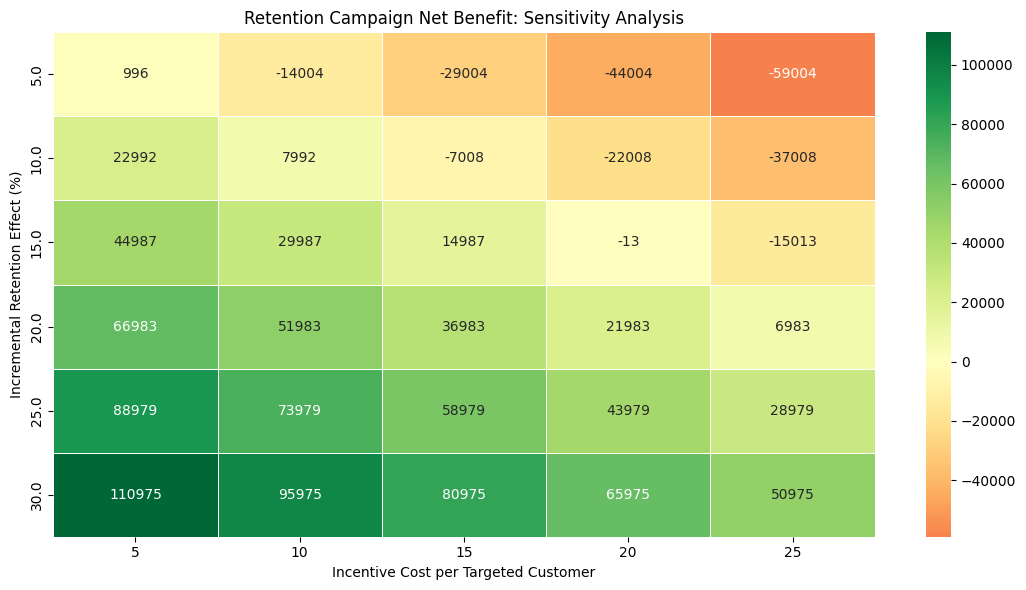


=== BREAK-EVEN RETENTION EFFECT BY COST ===


,Incentive_Cost,Break_Even_Retention_Effect_%
0,5,4.77
1,10,8.18
2,15,11.59
3,20,15.00
4,25,18.41


In [27]:
# Use top 20% risk group
target_group = financial_df.head(3000)

customers_targeted = len(target_group)

churner_monthly_revenue = target_group.loc[
    target_group["Actual_Churn"] == 1,
    "Monthly_Revenue_Proxy"
].sum()

# Fixed assumptions
MONTHS_RETAINED = 6
CONTRIBUTION_MARGIN = 0.60
CONTACT_COST = 2.0

# Sensitivity assumptions
retention_effects = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
incentive_costs = [5, 10, 15, 20, 25]

results = []

for effectiveness in retention_effects:
    for incentive in incentive_costs:

        retained_contribution = (
            churner_monthly_revenue
            * effectiveness
            * MONTHS_RETAINED
            * CONTRIBUTION_MARGIN
        )

        campaign_cost = customers_targeted * (
            CONTACT_COST + incentive
        )

        net_benefit = retained_contribution - campaign_cost

        results.append({
            "Retention_Effect_%": effectiveness * 100,
            "Incentive_Cost": incentive,
            "Net_Benefit": net_benefit
        })

sensitivity_df = pd.DataFrame(results)

# Create sensitivity table
sensitivity_pivot = sensitivity_df.pivot(
    index="Retention_Effect_%",
    columns="Incentive_Cost",
    values="Net_Benefit"
)

print("=== FINANCIAL SENSITIVITY TABLE ===")
display(sensitivity_pivot.round(2))

# Heatmap
plt.figure(figsize=(11, 6))

sns.heatmap(
    sensitivity_pivot,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5
)

plt.title("Retention Campaign Net Benefit: Sensitivity Analysis")
plt.xlabel("Incentive Cost per Targeted Customer")
plt.ylabel("Incremental Retention Effect (%)")
plt.tight_layout()
plt.show()

print("\n=== BREAK-EVEN RETENTION EFFECT BY COST ===")

break_even_results = []

for incentive in incentive_costs:

    cost = customers_targeted * (
        CONTACT_COST + incentive
    )

    break_even = cost / (
        churner_monthly_revenue
        * MONTHS_RETAINED
        * CONTRIBUTION_MARGIN
    )

    break_even_results.append({
        "Incentive_Cost": incentive,
        "Break_Even_Retention_Effect_%": break_even * 100
    })

display(pd.DataFrame(break_even_results).round(2))

In [28]:
priority_df = financial_df.copy()

# Expected monthly revenue exposure proxy
priority_df["Revenue_At_Risk_Score"] = (
    priority_df["Predicted_Probability"]
    * priority_df["Monthly_Revenue_Proxy"]
)

strategies = {
    "Risk Only": "Predicted_Probability",
    "Value Aware": "Revenue_At_Risk_Score"
}

results = []

for strategy_name, ranking_col in strategies.items():

    ranked = priority_df.sort_values(
        ranking_col,
        ascending=False
    )

    for pct in [10, 20]:

        n = int(len(ranked) * pct / 100)
        group = ranked.head(n)

        results.append({
            "Strategy": strategy_name,
            "Target_%": pct,
            "Customers": n,
            "Observed_Churners": int(
                group["Actual_Churn"].sum()
            ),
            "Observed_Churn_Rate_%":
                group["Actual_Churn"].mean() * 100,
            "Total_Monthly_Revenue":
                group["Monthly_Revenue_Proxy"].sum(),
            "Churner_Monthly_Revenue":
                group.loc[
                    group["Actual_Churn"] == 1,
                    "Monthly_Revenue_Proxy"
                ].sum()
        })

priority_comparison = pd.DataFrame(results)

print("=== TARGETING STRATEGY COMPARISON ===")
display(
    priority_comparison.sort_values(
        ["Target_%", "Strategy"]
    ).round(2)
)

print("\n=== INTERPRETATION ===")
print(
    "Risk-only ranks by churn probability."
)
print(
    "Value-aware ranks by probability multiplied "
    "by monthly revenue proxy."
)
print(
    "Results are retrospective and do not "
    "measure intervention effectiveness."
)

=== TARGETING STRATEGY COMPARISON ===


,Strategy,Target_%,Customers,Observed_Churners,Observed_Churn_Rate_%,Total_Monthly_Revenue,Churner_Monthly_Revenue
0,Risk Only,10,1500,1193,79.53,79060.96,62363.07
2,Value Aware,10,1500,906,60.40,220521.75,128284.33
1,Risk Only,20,3000,2191,73.03,168503.17,122198.84
3,Value Aware,20,3000,1798,59.93,346856.09,199532.58



=== INTERPRETATION ===
Risk-only ranks by churn probability.
Value-aware ranks by probability multiplied by monthly revenue proxy.
Results are retrospective and do not measure intervention effectiveness.


In [29]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Pilot setup
TOTAL_PILOT_CUSTOMERS = 3000
CONTROL_SHARE = 0.50

n_control = int(TOTAL_PILOT_CUSTOMERS * CONTROL_SHARE)
n_treatment = TOTAL_PILOT_CUSTOMERS - n_control

alpha = 0.05
power = 0.80

# Illustrative baseline churn rates
baseline_rates = [0.10, 0.20, 0.30, 0.50]

power_analysis = NormalIndPower()

results = []

for baseline_rate in baseline_rates:

    # Find minimum absolute churn reduction
    # detectable with 80% power
    low = 0.00001
    high = baseline_rate - 0.00001

    for _ in range(60):
        mid = (low + high) / 2

        treatment_rate = baseline_rate - mid

        effect_size = abs(
            proportion_effectsize(
                baseline_rate,
                treatment_rate
            )
        )

        achieved_power = power_analysis.power(
            effect_size=effect_size,
            nobs1=n_control,
            alpha=alpha,
            ratio=n_treatment / n_control,
            alternative="two-sided"
        )

        if achieved_power >= power:
            high = mid
        else:
            low = mid

    # Confirm achieved power
    detectable_effect_pp = high * 100

    results.append({
        "Baseline_Churn_%": baseline_rate * 100,
        "Treatment_Churn_%":
            (baseline_rate - high) * 100,
        "Detectable_Reduction_pp":
            detectable_effect_pp,
        "Relative_Reduction_%":
            high / baseline_rate * 100
    })

pilot_power_df = pd.DataFrame(results)

print("=== PILOT EXPERIMENT DESIGN ===")
print("Total customers:", TOTAL_PILOT_CUSTOMERS)
print("Control customers:", n_control)
print("Treatment customers:", n_treatment)
print("Significance level:", alpha)
print("Target statistical power:", power)

print("\n=== MINIMUM DETECTABLE CHURN REDUCTION ===")
display(pilot_power_df.round(2))

print("\n=== IMPORTANT NOTE ===")
print(
    "Results are approximate power calculations "
    "for independent, equal-sized randomized groups."
)

=== PILOT EXPERIMENT DESIGN ===
Total customers: 3000
Control customers: 1500
Treatment customers: 1500
Significance level: 0.05
Target statistical power: 0.8

=== MINIMUM DETECTABLE CHURN REDUCTION ===


,Baseline_Churn_%,Treatment_Churn_%,Detectable_Reduction_pp,Relative_Reduction_%
0,10.0,7.15,2.85,28.55
1,20.0,16.07,3.93,19.64
2,30.0,25.42,4.58,15.25
3,50.0,44.89,5.11,10.21



=== IMPORTANT NOTE ===
Results are approximate power calculations for independent, equal-sized randomized groups.


In [30]:
# Pilot size
PILOT_TOTAL = 3000
TREATMENT_N = 1500
CONTROL_N = 1500

# Previous financial assumptions
MONTHS_RETAINED = 6
CONTRIBUTION_MARGIN = 0.60
CONTACT_COST = 2.0
INCENTIVE_COST = 15.0

# Use top 20% risk group for illustrative pilot
pilot_group = financial_df.head(PILOT_TOTAL)

# Observed historical churn prevalence (NOT an estimated treatment effect)
historical_churn_rate = pilot_group["Actual_Churn"].mean()

# Average monthly revenue proxy among historical churners
average_churner_revenue = pilot_group.loc[
    pilot_group["Actual_Churn"] == 1,
    "Monthly_Revenue_Proxy"
].mean()

# Hypothetical relative churn reductions
relative_effects = [0.05, 0.10, 0.15, 0.20, 0.25]

pilot_results = []

for effect in relative_effects:

    # Expected number of churn cases prevented
    expected_prevented = (
        TREATMENT_N
        * historical_churn_rate
        * effect
    )

    # Expected incremental contribution
    benefit = (
        expected_prevented
        * average_churner_revenue
        * MONTHS_RETAINED
        * CONTRIBUTION_MARGIN
    )

    # Only treated customers receive the intervention
    treatment_cost = TREATMENT_N * (
        CONTACT_COST + INCENTIVE_COST
    )

    net_benefit = benefit - treatment_cost

    pilot_results.append({
        "Relative_Churn_Reduction_%": effect * 100,
        "Expected_Prevented_Churns": expected_prevented,
        "Incremental_Contribution": benefit,
        "Treatment_Cost": treatment_cost,
        "Net_Benefit": net_benefit
    })

pilot_business_df = pd.DataFrame(pilot_results)

print("=== PILOT ASSUMPTIONS ===")
print("Total participants:", PILOT_TOTAL)
print("Treatment customers:", TREATMENT_N)
print("Control customers:", CONTROL_N)
print("Historical sample churn rate:",
      round(historical_churn_rate * 100, 2), "%")
print("Average monthly revenue proxy of churners:",
      round(average_churner_revenue, 2))

print("\n=== PILOT FINANCIAL SCENARIOS ===")
display(pilot_business_df.round(2))

# Break-even relative effect
break_even_effect = (
    TREATMENT_N * (CONTACT_COST + INCENTIVE_COST)
) / (
    TREATMENT_N
    * historical_churn_rate
    * average_churner_revenue
    * MONTHS_RETAINED
    * CONTRIBUTION_MARGIN
)

print("\n=== PILOT BREAK-EVEN ===")
print(
    "Required relative churn reduction:",
    round(break_even_effect * 100, 2), "%"
)

print("\nNote: These are hypothetical expected values.")
print("No actual intervention outcomes have been observed.")

=== PILOT ASSUMPTIONS ===
Total participants: 3000
Treatment customers: 1500
Control customers: 1500
Historical sample churn rate: 73.03 %
Average monthly revenue proxy of churners: 55.77

=== PILOT FINANCIAL SCENARIOS ===


,Relative_Churn_Reduction_%,Expected_Prevented_Churns,Incremental_Contribution,Treatment_Cost,Net_Benefit
0,5.0,54.78,10997.90,25500.0,-14502.10
1,10.0,109.55,21995.79,25500.0,-3504.21
2,15.0,164.32,32993.69,25500.0,7493.69
3,20.0,219.10,43991.58,25500.0,18491.58
4,25.0,273.88,54989.48,25500.0,29489.48



=== PILOT BREAK-EVEN ===
Required relative churn reduction: 11.59 %

Note: These are hypothetical expected values.
No actual intervention outcomes have been observed.


In [31]:
from pathlib import Path

output_dir = Path("/kaggle/working/final_assignment_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

tables_to_save = {
    "model_comparison": comparison_all,
    "final_test_metrics": pd.DataFrame([final_test_results]),
    "segment_analysis": segment_detail,
    "feature_importance": importance_df,
    "test_targeting": test_targeting_summary,
    "targeting_strategy_comparison": priority_comparison,
    "financial_scenarios": scenario_df,
    "financial_sensitivity": sensitivity_df,
    "pilot_power": pilot_power_df,
    "pilot_financial_scenarios": pilot_business_df
}

print("=== EXPORTING ANALYSIS RESULTS ===")

for name, table in tables_to_save.items():
    path = output_dir / f"{name}.csv"
    table.to_csv(path, index=False)
    print(f"Saved: {path.name} | Shape: {table.shape}")

print("\n=== OUTPUT VERIFICATION ===")

saved_files = sorted(output_dir.glob("*.csv"))

print("Number of CSV files:", len(saved_files))

for path in saved_files:
    print(f"{path.name}: {path.stat().st_size:,} bytes")

assert len(saved_files) == len(tables_to_save)

print("\nAll results exported successfully!")

=== EXPORTING ANALYSIS RESULTS ===
Saved: model_comparison.csv | Shape: (3, 8)
Saved: final_test_metrics.csv | Shape: (1, 8)
Saved: segment_analysis.csv | Shape: (9, 8)
Saved: feature_importance.csv | Shape: (272, 3)
Saved: test_targeting.csv | Shape: (4, 6)
Saved: targeting_strategy_comparison.csv | Shape: (4, 7)
Saved: financial_scenarios.csv | Shape: (3, 8)
Saved: financial_sensitivity.csv | Shape: (30, 3)
Saved: pilot_power.csv | Shape: (4, 4)
Saved: pilot_financial_scenarios.csv | Shape: (5, 5)

=== OUTPUT VERIFICATION ===
Number of CSV files: 10
feature_importance.csv: 13,970 bytes
final_test_metrics.csv: 213 bytes
financial_scenarios.csv: 432 bytes
financial_sensitivity.csv: 822 bytes
model_comparison.csv: 516 bytes
pilot_financial_scenarios.csv: 430 bytes
pilot_power.csv: 318 bytes
segment_analysis.csv: 1,090 bytes
targeting_strategy_comparison.csv: 398 bytes
test_targeting.csv: 342 bytes

All results exported successfully!
